# Reading and running `FullSurrogate.fmu`

`FullSurrogate.fmu` is a **SmartUQ** surrogate exported as an **FMI 3.0 Co-Simulation** FMU.

## Why this notebook looks different from a stock fmpy notebook

| Fact | Consequence |
|---|---|
| It ships **only** `binaries/x86_64-windows/fmi3.dll` | `fmpy.simulate_fmu()` on Linux fails with *"The FMU cannot be simulated on the current platform (linux64)"* |
| Its surrogate payload (`resources/Model.smartuq`) is **AES-encrypted** | The model cannot be liberated into a native Python surrogate (the HDF5 root carries an `iv` attribute and every numeric dataset uses a custom filter) |
| fmpy's Linux->Wine remoting bridge is **FMI 2.0 only** | It cannot carry this FMI 3.0 FMU, no matter how it is configured |

**Solution used here:** run the Windows DLL under Wine via a stdlib-only FMI 3.0
driver (`fmi3_wine.py`), wrapped by `surrogate_fmu.py`. The model *description*
is read natively (the XML is not encrypted), so the inspection cells below work
on any OS with no Wine at all; only the *simulation* cells need Wine.

> **Cleaner alternative (if SmartUQ access is available):** re-export the FMU with a
> Linux binary (`binaries/x86_64-linux/fmi3.so`). Everything here keeps working
> unchanged afterwards.


In [1]:
# --- Inspection needs no Wine: the XML inside the FMU is not encrypted ---
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

from surrogate_fmu import Surrogate, read_model_description, NOMINAL_INPUTS

FMU = "FullSurrogate.fmu"
mdesc = read_model_description(FMU)

print(f"Model name       : {mdesc['model_name']}")
print(f"FMI version      : {mdesc['fmi_version']}")
print(f"Generation tool  : {mdesc['generation_tool']}")
print(f"Default experiment: {mdesc['default_experiment']}")
print(f"\nInputs ({len(mdesc['inputs'])}):")
for v in mdesc["inputs"]:
    print(f"   {v['name']:<28} (start = {v['start']})")
print(f"\nOutputs ({len(mdesc['outputs'])}):")
for v in mdesc["outputs"]:
    print(f"   {v['name']}")

Model name       : FullSurrogate
FMI version      : 3.0
Generation tool  : SmartUQ
Default experiment: {'startTime': 0.0, 'stopTime': 1.0, 'stepSize': 1.0}

Inputs (18):
   I_coil_rms (A)               (start = 0.0)
   F_coil (Hz)                  (start = 0.0)
   alpha_tb (deg)               (start = 0.0)
   beta_tb (deg)                (start = 0.0)
   dx (mm)                      (start = 0.0)
   dy (mm)                      (start = 0.0)
   dz (mm)                      (start = 0.0)
   T_cool_sample (degC)         (start = 0.0)
   HTC_sample                   (start = 0.0)
   St_alpha_scaling             (start = 0.0)
   St_sigma_scaling             (start = 0.0)
   St_k_scaling                 (start = 0.0)
   St_E_scaling                 (start = 0.0)
   St_nu_scaling                (start = 0.0)
   St_cp_scaling                (start = 0.0)
   Cu_sigma_scaling             (start = 0.0)
   Cu_k_scaling                 (start = 0.0)
   Cu_rho_scaling               (start = 0.0)

O

## What is inside the FMU

The surrogate itself lives in `resources/Model.smartuq` (an HDF5 file) and is
readable only by SmartUQ's own `csmartuq.dll` - the numeric datasets are
encrypted, so the model cannot be reimplemented natively on Linux.

In [2]:
import zipfile

with zipfile.ZipFile(FMU) as z:
    for name in z.namelist():
        print(f"{name}  ({z.getinfo(name).file_size:,} bytes)")

binaries/  (0 bytes)
binaries/x86_64-windows/  (0 bytes)
binaries/x86_64-windows/fmi3.dll  (49,664 bytes)
documentation/  (0 bytes)
documentation/index.html  (1,015 bytes)
documentation/licenses/  (0 bytes)
documentation/licenses/eula.html  (54,845 bytes)
documentation/licenses/license.html  (568 bytes)
documentation/licenses/third-party.html  (197,459 bytes)
model.png  (24,832 bytes)
modelDescription.xml  (10,286 bytes)
resources/  (0 bytes)
resources/Model.smartuq  (8,294,144 bytes)
resources/csmartuq.dll  (36,401,664 bytes)
resources/blosc.dll  (100,352 bytes)
resources/hdf5.dll  (3,395,584 bytes)
resources/zlib1.dll  (84,992 bytes)


## Running the surrogate under Wine

`Surrogate` shells out to `fmi3_wine.py` inside a Windows Python running under
Wine. Requirements are checked automatically; see `README_surrogate.md` for the
one-time setup.

Note: every input has `start = 0`, which is a degenerate operating point
(zero conductivity scaling, zero coolant temperature, ...). The wrapper
therefore defaults to `NOMINAL_INPUTS` - scaling factors = 1, coolant = 25 degC.

In [3]:
s = Surrogate(FMU)
print(s)

# One evaluation at the nominal operating point, perturbed coil current.
result = s.evaluate({"I_coil_rms (A)": 150.0, "F_coil (Hz)": 50_000.0})

interesting = [
    "Temperature (degC), TC7",
    "Sample Maximum Temperature (degC)",
    "Sample Average Temperature (degC)",
    "Volumetric loss density, electromagnetic (W)",
    "V_coil_rms (V)",
]
for k in interesting:
    print(f"  {k:<50} {result[k]:.4g}")

<Surrogate FullSurrogate.fmu: 18 inputs, 40 outputs, backend=wine>
  Temperature (degC), TC7                            355.9
  Sample Maximum Temperature (degC)                  485.5
  Sample Average Temperature (degC)                  238.5
  Volumetric loss density, electromagnetic (W)       539.7
  V_coil_rms (V)                                     76.36


## Sweep: coil current vs. temperature / loss

Batch mode keeps **one** FMU instance alive across all points (roughly 250 ms per
point including Wine start-up; faster once warm), returning a `pandas.DataFrame`
with inputs and outputs side by side.

In [4]:
import time
import numpy as np

currents = np.linspace(1400, 1500, 11)
t0 = time.time()
df = s.evaluate_batch([{"I_coil_rms (A)": float(I)} for I in currents])
elapsed = time.time() - t0

print(f"{len(df)} points in {elapsed:.1f}s  ({1000*elapsed/len(df):.0f} ms/point)")
df[["I_coil_rms (A)",
    "Temperature (degC), TC7",
    "Sample Maximum Temperature (degC)",
    "Volumetric loss density, electromagnetic (W)"]]

11 points in 2.6s  (238 ms/point)


,I_coil_rms (A),"Temperature (degC), TC7",Sample Maximum Temperature (degC),"Volumetric loss density, electromagnetic (W)"
0,1400.0,341.089629,498.803862,395.971823
1,1410.0,343.731150,503.435918,401.977441
2,1420.0,346.398273,508.102948,408.050503
3,1430.0,349.089478,512.802168,414.182847
4,1440.0,351.803095,517.530528,420.368460
5,1450.0,354.537141,522.284439,426.605167
6,1460.0,357.289603,527.059559,432.893673
7,1470.0,360.059187,531.850784,439.236155
8,1480.0,362.845721,536.652602,445.636684
9,1490.0,365.649423,541.459793,452.099572


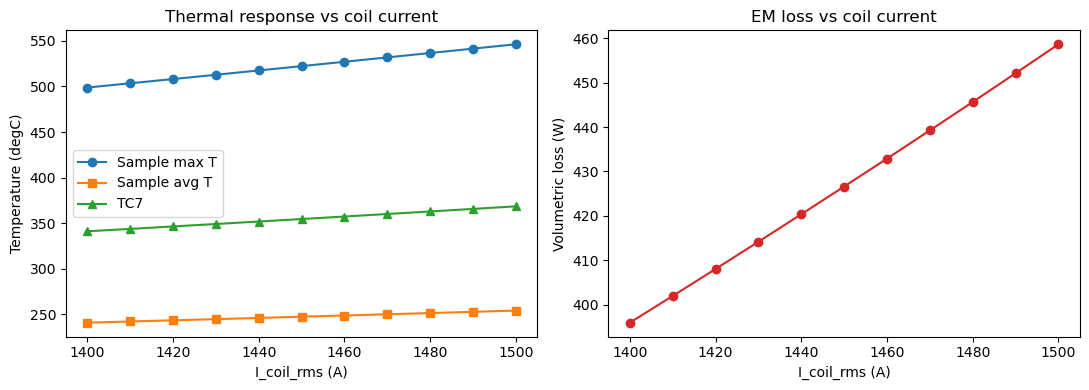

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(df["I_coil_rms (A)"], df["Sample Maximum Temperature (degC)"], "o-",
           label="Sample max T")
ax[0].plot(df["I_coil_rms (A)"], df["Sample Average Temperature (degC)"], "s-",
           label="Sample avg T")
ax[0].plot(df["I_coil_rms (A)"], df["Temperature (degC), TC7"], "^-", label="TC7")
ax[0].set_xlabel("I_coil_rms (A)"); ax[0].set_ylabel("Temperature (degC)")
ax[0].legend(); ax[0].set_title("Thermal response vs coil current")

ax[1].plot(df["I_coil_rms (A)"], df["Volumetric loss density, electromagnetic (W)"],
           "o-", color="tab:red")
ax[1].set_xlabel("I_coil_rms (A)")
ax[1].set_ylabel("Volumetric loss (W)")
ax[1].set_title("EM loss vs coil current")

fig.tight_layout()

## To remember

*  Need to stay inside the surrogate's design space.
* `fmi3DoStep` is deliberately not used: this FMU does not export
  `fmi3SetupExperiment` (a vendor deviation from the FMI 3.0 spec), so its stop
  time is never initialised. Being a static algebraic surrogate, its outputs are
  already computed after initialisation mode.
* The Wine prefix is about 1.3 GB. It lives at
  `~/.local/share/fullfieldvalmetrics/wineprefix` and survives reboots
  (deliberately *not* in `/tmp`).
